In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Load the cleaned listings data directly from CSV
df = pd.read_csv("Listings.csv", encoding="latin1")

# Convert any leftover 0 values in review score columns back to NaN
review_cols = [
    "review_scores_rating", "review_scores_accuracy", "review_scores_cleanliness",
    "review_scores_checkin", "review_scores_communication",
    "review_scores_location", "review_scores_value"
]
for col in review_cols:
    if col in df.columns:
        df[col] = df[col].replace(0, pd.NA)

print(f"Data loaded successfully! Rows: {len(df)}, Columns: {len(df.columns)}")

/tmp/ipykernel_16249/2739823227.py:7: DtypeWarning: Columns (5: host_response_time, 13: district) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Listings.csv", encoding="latin1")


Data loaded successfully! Rows: 279712, Columns: 33


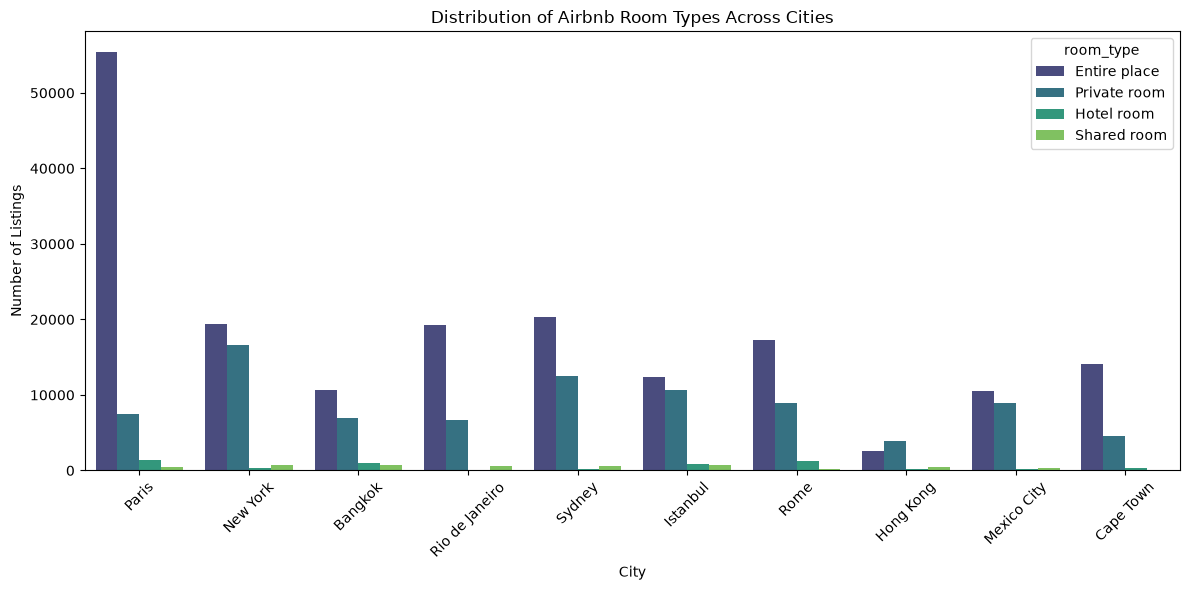

In [19]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='city', hue='room_type', palette='viridis')
plt.title('Distribution of Airbnb Room Types Across Cities')
plt.xlabel('City')
plt.ylabel('Number of Listings')
plt.xticks(rotation=45)
plt.tight_layout()

# Save and show
plt.savefig('Visualisations/cities_room_types.png', dpi=300, bbox_inches='tight') 
plt.show()

/tmp/ipykernel_16249/3409142840.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paris, x='room_type', y='price', palette='Set2')


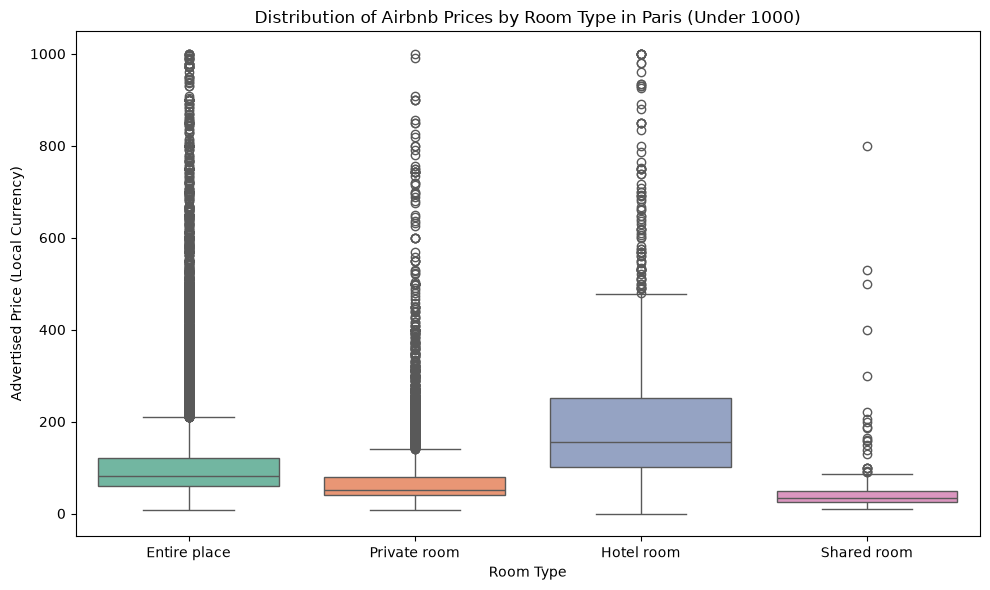

In [20]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_paris, x='room_type', y='price', palette='Set2')
plt.title('Distribution of Airbnb Prices by Room Type in Paris (Under 1000)')
plt.xlabel('Room Type')
plt.ylabel('Advertised Price (Local Currency)')
plt.tight_layout()

# Save and show
plt.savefig('Visualisations/paris_roomtype_price.png', dpi=300, bbox_inches='tight') 
plt.show()

/tmp/ipykernel_16249/297763678.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_paris, x='accommodates', y='price', palette='coolwarm')


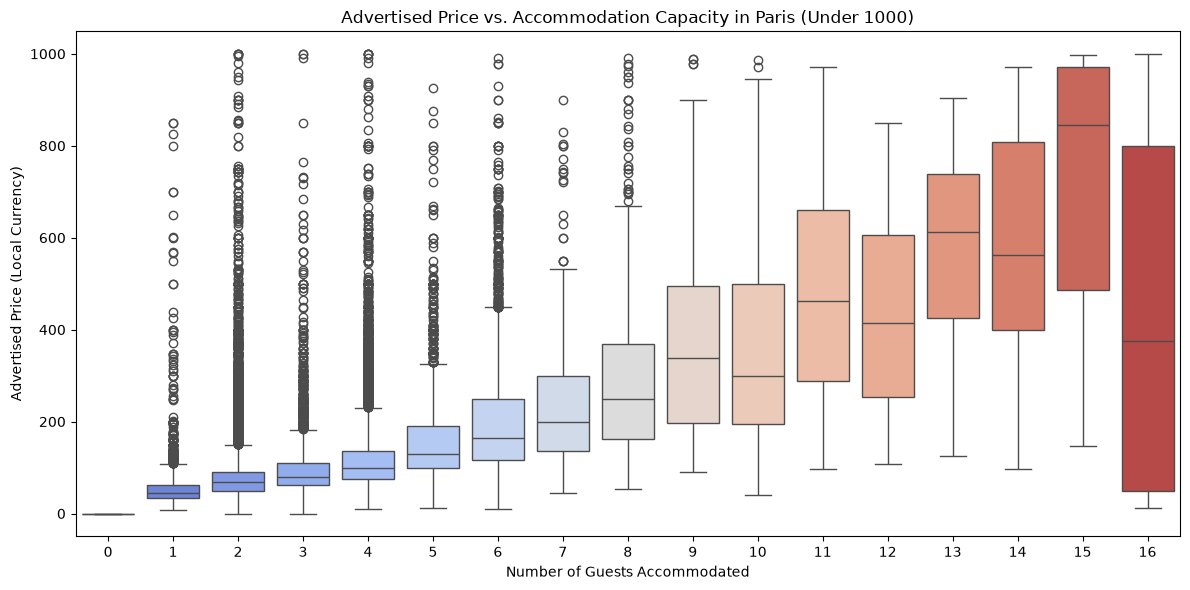

In [21]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_paris, x='accommodates', y='price', palette='coolwarm')
plt.title('Advertised Price vs. Accommodation Capacity in Paris (Under 1000)')
plt.xlabel('Number of Guests Accommodated')
plt.ylabel('Advertised Price (Local Currency)')
plt.tight_layout()

# Save and show
plt.savefig('Visualisations/paris_capacity_price.png', dpi=300, bbox_inches='tight') 
plt.show()

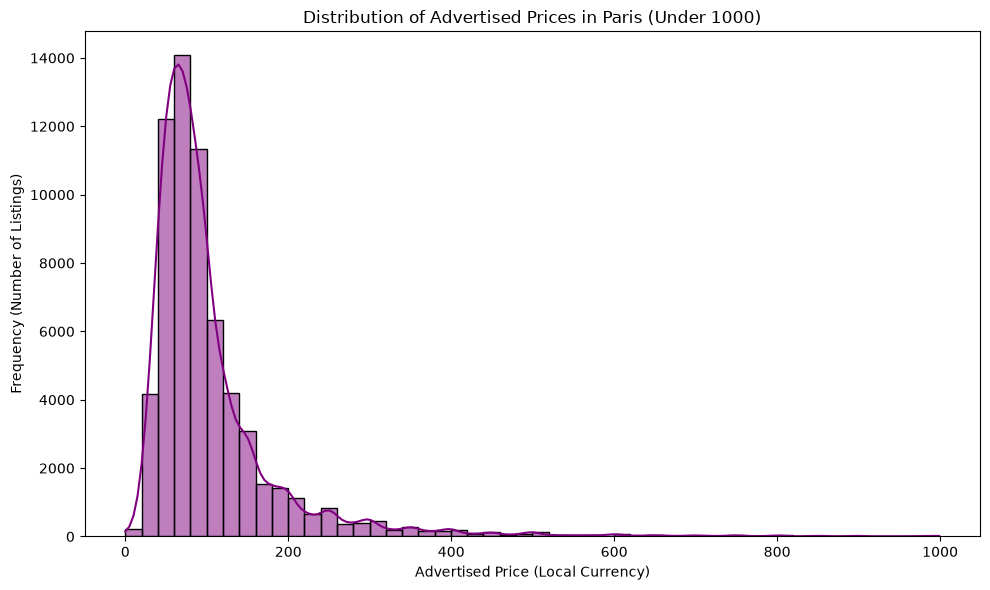

In [22]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df_paris, x='price', bins=50, kde=True, color='purple')
plt.title('Distribution of Advertised Prices in Paris (Under 1000)')
plt.xlabel('Advertised Price (Local Currency)')
plt.ylabel('Frequency (Number of Listings)')
plt.tight_layout()

# Save and show
plt.savefig('Visualisations/paris_price_histogram.png', dpi=300, bbox_inches='tight') 
plt.show()

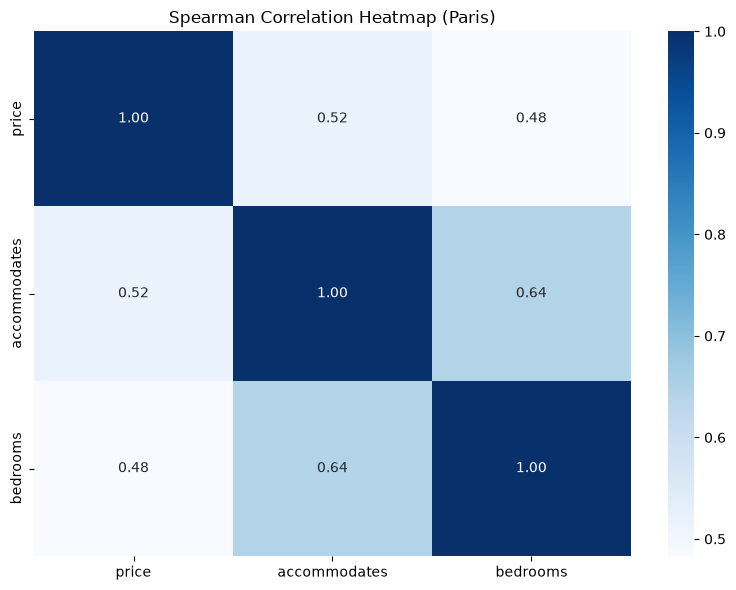

In [23]:
plt.figure(figsize=(8, 6))
# Select numerical columns and drop missing values for accurate correlation
numeric_cols = df_paris[['price', 'accommodates', 'bedrooms']].dropna()
correlation_matrix = numeric_cols.corr(method='spearman')

sns.heatmap(correlation_matrix, annot=True, cmap='Blues', fmt='.2f')
plt.title('Spearman Correlation Heatmap (Paris)')
plt.tight_layout()

# Save and show
plt.savefig('Visualisations/paris_correlation_heatmap.png', dpi=300, bbox_inches='tight') 
plt.show()

In [24]:
print("Null Hypothesis (H0): Advertised prices are equal across all room types in Paris.")
print("Alternative Hypothesis (H1): Advertised prices significantly differ across at least one room type in Paris.\n")

# Prepare the data by grouping prices by room type
groups = [group['price'].values for name, group in df_paris.groupby('room_type')]

# Run the Kruskal-Wallis Test
stat, p_value = stats.kruskal(*groups)

print(f"Kruskal-Wallis H-statistic: {stat:.4f}")
print(f"P-value: {p_value:.4e}")

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis. There is a statistically significant difference in advertised prices across room types.")
else:
    print("\nConclusion: Fail to reject the null hypothesis. No significant difference found.")

Null Hypothesis (H0): Advertised prices are equal across all room types in Paris.
Alternative Hypothesis (H1): Advertised prices significantly differ across at least one room type in Paris.

Kruskal-Wallis H-statistic: 5089.0880
P-value: 0.0000e+00

Conclusion: Reject the null hypothesis. There is a statistically significant difference in advertised prices across room types.


In [25]:
# Clean missing bedroom data for the tests
df_paris_clean = df_paris.dropna(subset=['bedrooms', 'accommodates', 'price'])

# Hypothesis 2: Capacity vs Price
print("H0: There is no correlation between accommodation capacity and advertised price.")
stat_acc, p_acc = stats.spearmanr(df_paris_clean['accommodates'], df_paris_clean['price'])
print(f"Capacity Spearman Correlation: {stat_acc:.4f}, P-value: {p_acc:.4e}")

# Hypothesis 3: Bedrooms vs Price
print("\nH0: There is no correlation between the number of bedrooms and advertised price.")
stat_bed, p_bed = stats.spearmanr(df_paris_clean['bedrooms'], df_paris_clean['price'])
print(f"Bedrooms Spearman Correlation: {stat_bed:.4f}, P-value: {p_bed:.4e}")

if p_acc < 0.05 and p_bed < 0.05:
    print("\nConclusion: Reject both null hypotheses. Capacity and bedrooms are significantly positively correlated with price.")

H0: There is no correlation between accommodation capacity and advertised price.
Capacity Spearman Correlation: 0.5167, P-value: 0.0000e+00

H0: There is no correlation between the number of bedrooms and advertised price.
Bedrooms Spearman Correlation: 0.4832, P-value: 0.0000e+00

Conclusion: Reject both null hypotheses. Capacity and bedrooms are significantly positively correlated with price.
